# GPT-Image-2 image editing

### Installing Required Libraries

In [ ]:
%pip install -q openai pillow

### Setting up the Environment

In [10]:
from pathlib import Path
from dotenv import load_dotenv
import os

load_dotenv()

AZURE_OPENAI_ENDPOINT = os.getenv("AZURE_OPENAI_ENDPOINT")

AZURE_OPENAI_IMAGE_DEPLOYMENT = os.getenv("AZURE_OPENAI_IMAGE_DEPLOYMENT")
AZURE_OPENAI_API_KEY = os.getenv("AZURE_OPENAI_API_KEY")

print(AZURE_OPENAI_ENDPOINT)
print(AZURE_OPENAI_IMAGE_DEPLOYMENT)

https://udemo-103-resource.openai.azure.com/
gpt-image-2


### Helpers: save + display

In [11]:
from pathlib import Path
from PIL import Image, ImageDraw

OUTPUT_DIR = Path("images_edit")
OUTPUT_DIR.mkdir(exist_ok=True)


def show(path: Path):
    display(Image.open(path))


def save_b64_png(b64_data: str, out_path: Path) -> Path:
    import base64
    out_path.write_bytes(base64.b64decode(b64_data))
    return out_path


def create_rect_inpaint_mask(base_image_path: Path, rect, out_mask_path: Path) -> Path:
    """
    rect = (x0, y0, x1, y1) in pixels.
    Mask rules (per Learn): transparent pixels indicate areas to edit.
    """
    base = Image.open(base_image_path).convert("RGBA")
    w, h = base.size

    # Start with fully opaque (keep everything)
    mask = Image.new("RGBA", (w, h), (255, 255, 255, 255))

    # Make the edit area fully transparent
    draw = ImageDraw.Draw(mask)
    draw.rectangle(rect, fill=(0, 0, 0, 0))

    mask.save(out_mask_path)
    return out_mask_path

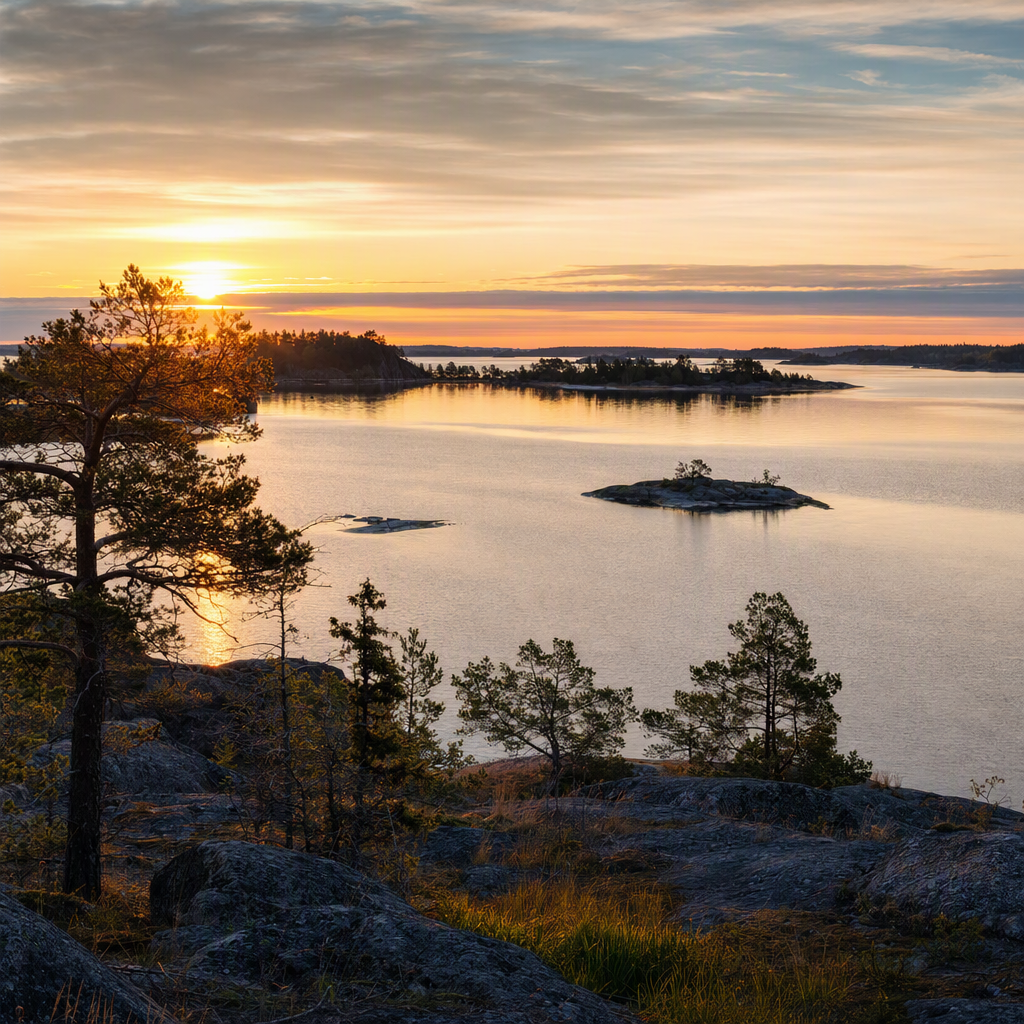

In [12]:
input_image_path = Path("images/img.png")
if not input_image_path.exists():
    raise FileNotFoundError(f"Input image not found: {input_image_path}")

show(input_image_path)

In [13]:
from pathlib import Path
from PIL import Image, ImageDraw

OUTPUT_DIR = Path("images_edit")
OUTPUT_DIR.mkdir(exist_ok=True)


def show(path: Path):
    display(Image.open(path))


def save_b64_png(b64_data: str, out_path: Path) -> Path:
    import base64
    out_path.write_bytes(base64.b64decode(b64_data))
    return out_path


def create_rect_inpaint_mask(base_image_path: Path, rect, out_mask_path: Path) -> Path:
    """
    rect = (x0, y0, x1, y1) in pixels.
    Mask rules (per Learn): transparent pixels indicate areas to edit.
    """
    base = Image.open(base_image_path).convert("RGBA")
    w, h = base.size

    # Start with fully opaque (keep everything)
    mask = Image.new("RGBA", (w, h), (255, 255, 255, 255))

    # Make the edit area fully transparent
    draw = ImageDraw.Draw(mask)
    draw.rectangle(rect, fill=(0, 0, 0, 0))

    mask.save(out_mask_path)
    return out_mask_path

### Create a mask (same size as the image)

Mask saved to: images_edit\mask.png


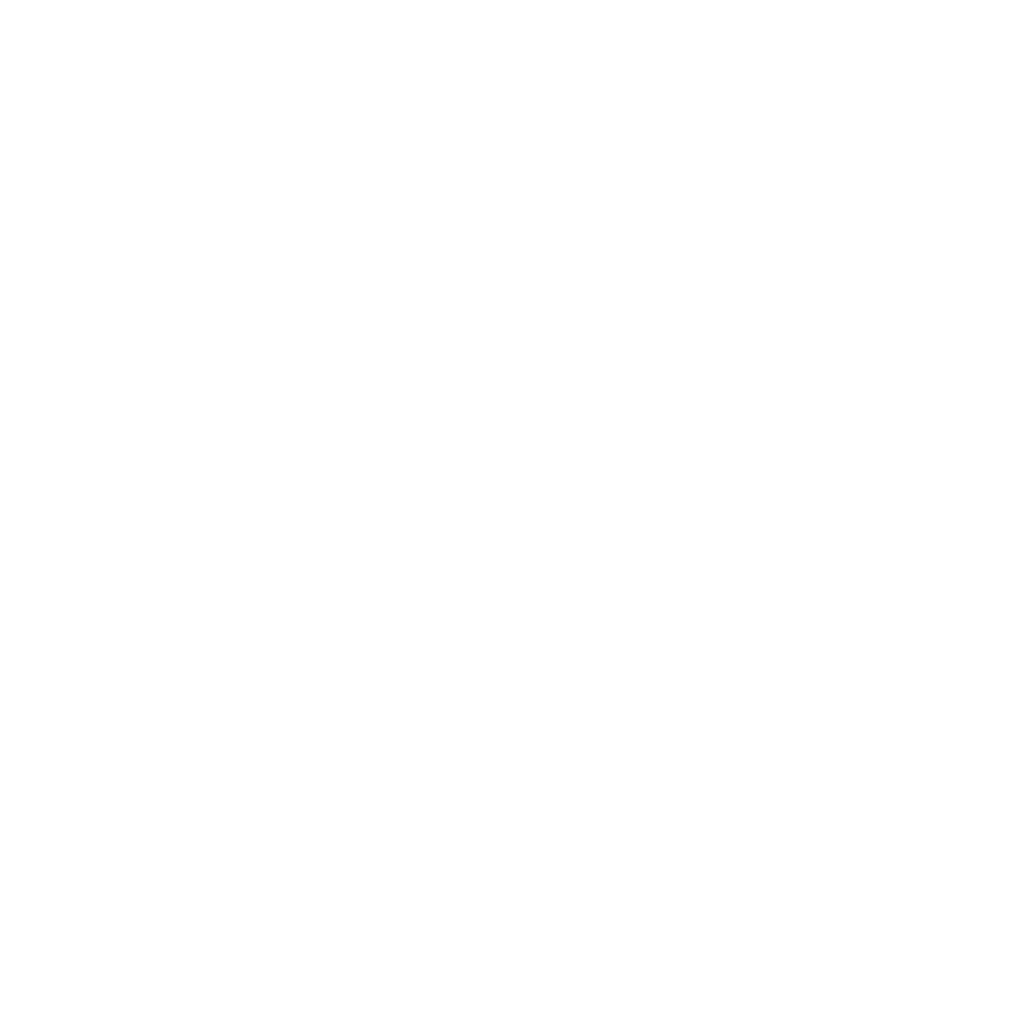

In [14]:
mask_path = OUTPUT_DIR / "mask.png"

# Example rectangle area to edit (x0, y0, x1, y1) — tweak for your image
rect = (300, 300, 750, 750)

create_rect_inpaint_mask(input_image_path, rect, mask_path)

print("Mask saved to:", mask_path)
show(mask_path)

### Generate single image

In [15]:
import requests

edit_url = (
    f"{AZURE_OPENAI_ENDPOINT}openai/deployments/{AZURE_OPENAI_IMAGE_DEPLOYMENT}/images/edits"
    f"?api-version=2025-04-01-preview"
)

prompt = "Replace the masked area with a small red wooden cabin, matching the lighting and perspective."

data = {
    "prompt": prompt,
    "n": 1,
    "size": "1024x1024",
    "quality": "high",
    # Some deployments support additional fields (varies); keep it simple for reliability
}

files = {
    # name and content type matter; image must be PNG or JPG per Learn doc
    "image": (input_image_path.name, open(input_image_path, "rb"), "image/png"),
    "mask": (mask_path.name, open(mask_path, "rb"), "image/png"),
}

resp = requests.post(
    edit_url,
    headers={
        "api-key": AZURE_OPENAI_API_KEY,
    },
    data=data,
    files=files,
)

print("Status:", resp.status_code)
print("Response (truncated):", resp.text[:500])
resp.raise_for_status()

result = resp.json()
result.keys()

Status: 200
Response (truncated): {
  "created": 1792158520,
  "background": "opaque",
  "data": [
    {
      "b64_json": "iVBORw0KGgoAAAANSUhEUgAABAAAAAQACAIAAADwf7zUAABJ+mNhQlgAAEn6anVtYgAAAB5qdW1kYzJwYQARABCAAACqADibcQNjMnBhAAAASdRqdW1iAAAAR2p1bWRjMm1hABEAEIAAAKoAOJtxA3VybjpjMnBhOmEzZmNkZWQ2LTJjOGEtNGQ0Ni04ZjA3LTA5ZmJhOGU0YzgxZAAAAAQIanVtYgAAAClqdW1kYzJhcwARABCAAACqADibcQNjMnBhLmFzc2VydGlvbnMAAAAB/Wp1bWIAAABBanVtZGNib3IAEQAQgAAAqgA4m3ETYzJwYS5hY3Rpb25zLnYyAAAAABhjMnNoNwaUYQmRNyNVJ8DSlDKmbgAAAbRjYm9yomdhY3Rpb25zgqVmYWN0aW9ubG


dict_keys(['created', 'background', 'data', 'output_format', 'quality', 'size', 'usage'])

Edited image saved to: images_edit\edited_result.png


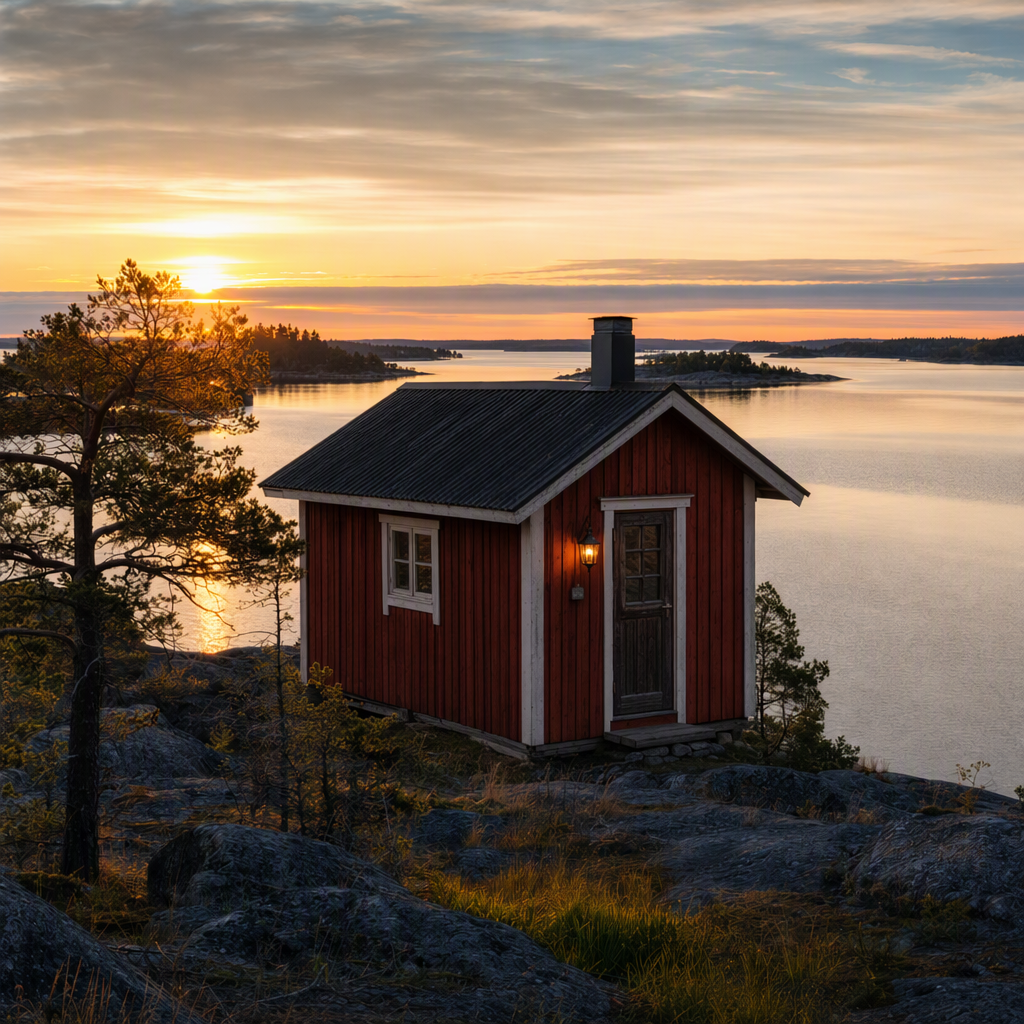

In [16]:
edited_image_path = OUTPUT_DIR / "edited_result.png"
save_b64_png(result["data"][0]["b64_json"], edited_image_path)
print("Edited image saved to:", edited_image_path)
show(edited_image_path)